<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Controle de Processos com Python — Simulação Dinâmica e Controladores PID.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

Em processos químicos, a operação segura e consistente depende da capacidade de manter variáveis próximas de condições desejadas, mesmo diante de perturbações. Um controlador não altera diretamente a temperatura ou a concentração: ele atua sobre uma variável manipulada e depende de um modelo, de medições e da dinâmica do processo.

Neste notebook, desenvolveremos **modelos e algoritmos antes de recorrer a funções prontas**. Partiremos de um balanço de energia simplificado, estudaremos as ações proporcional, integral e derivativa, construiremos um simulador em Python e interpretaremos seus resultados. Os parâmetros são didáticos: os códigos **não devem ser utilizados para operar equipamentos reais**, dimensionar sistemas de proteção ou substituir análise de segurança.

**Objetivos:** distinguir malha aberta e fechada, compreender respostas transitórias, implementar controladores P, PI e PID, avaliar saturação e anti-windup e comparar o desempenho frente a mudanças de referência e perturbações.

**Sumário**

1. [O problema de controle em Engenharia Química](#secao-1)
2. [Preparação e organização das simulações](#secao-2)
3. [Variáveis de processo e malha de realimentação](#secao-3)
4. [Modelo dinâmico de primeira ordem](#secao-4)
5. [Resposta ao degrau em malha aberta](#secao-5)
6. [Discretização por Euler e validação](#secao-6)
7. [Controle proporcional: lei e interpretação](#secao-7)
8. [Simulação de controle P em malha fechada](#secao-8)
9. [Erro estacionário e ação proporcional](#secao-9)
10. [Controle integral e eliminação do offset](#secao-10)
11. [Controle derivativo e antecipação](#secao-11)
12. [Controlador PID e discretização](#secao-12)
13. [Saturação do atuador e windup](#secao-13)
14. [Anti-windup por integração condicional](#secao-14)
15. [Perturbações e rejeição de carga](#secao-15)
16. [Sintonia e comparação de desempenhos](#secao-16)
17. [Instrumentação: ruído e filtragem](#secao-17)
18. [Aplicação integradora: tanque aquecido](#secao-18)
19. [Exercícios de consolidação](#secao-19)
20. [Conclusões](#secao-20)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. O problema de controle em Engenharia Química</div>

**Problema de Engenharia.** Um tanque aquecido deve manter sua temperatura próxima de uma referência, apesar de mudanças na alimentação ou na perda de calor. A variável controlada é a temperatura $T$; a variável manipulada é a potência térmica fornecida; uma perturbação pode ser uma alteração na temperatura de entrada.

A pergunta central não é apenas **qual potência aplicar**, mas **como a temperatura evolui ao longo do tempo** e como a ação do controlador altera essa evolução.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Preparação e organização das simulações</div>

Utilizaremos `numpy` para cálculos vetoriais e `matplotlib` para gráficos. As bibliotecas podem ser instaladas no terminal com `python -m pip install numpy matplotlib`. O modelo é integrado com um algoritmo explícito, permitindo ao estudante acompanhar cada atualização.

Para manter a interpretação física, expressaremos o tempo em minutos, a temperatura em °C e o sinal de controle como uma potência térmica normalizada em unidades didáticas.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Variáveis de processo e malha de realimentação</div>

Em uma malha de realimentação, a referência $r(t)$ é comparada à variável medida $y(t)$, produzindo o erro

$$e(t)=r(t)-y(t).$$

O controlador transforma o erro em ação $u(t)$; a planta responde segundo sua dinâmica; o sensor informa a nova condição.

**Exemplo manual:** se $r=80$ °C e $y=74$ °C, então $e=80-74=6$ °C. O sinal positivo indica que a temperatura está abaixo da referência, mas a direção correta da ação depende do sinal do ganho do processo.

In [18]:
referencia_C = 80.0
medicao_C = 74.0
erro_C = referencia_C - medicao_C
print(f"Erro de controle: {erro_C:+.1f} °C")

Erro de controle: +6.0 °C


<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Modelo dinâmico de primeira ordem</div>

**Modelo fenomenológico simplificado.** Para um tanque bem misturado com capacidade térmica efetiva $C$, perdas térmicas proporcionais à diferença para o ambiente e potência manipulada $q$, o balanço de energia é

$$
C\ \frac{dT}{dt}=q-UA(T-T_a)
$$

Dividindo por $UA$ e definindo $\ \tau=C/(UA)$, $K=1/(UA)$, obtemos

$$\ \tau\ \frac{dT}{dt}=-(T-T_a)+Kq.$$

Em variáveis de desvio $x=T-T_a$ e $u=q$, o modelo é

$$\ \tau\ \frac{dx}{dt}=-x+Ku.$$

O ganho $K$ tem unidades de °C por unidade de controle, e $\ \tau$ é a constante de tempo em minutos. Este modelo ignora variações de propriedades, atrasos e limitações de transferência de calor.

<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Resposta ao degrau em malha aberta</div>

Para uma entrada constante $u_0$ e condição inicial $x(0)=x_0$, a solução analítica é

$$x(t)=Ku_0+(x_0-Ku_0)e^{-t/\\tau}.$$

Considere $\\tau=5$ min, $K=2$ °C/unidade, $u_0=10$ unidades e $x_0=0$. O valor final é $Ku_0=20$ °C acima do ambiente. Após uma constante de tempo, a resposta alcança aproximadamente 63,2% da variação: $x(5)=20(1-e^{-1})\\approx12{,}64$ °C.

Elevação após 5 min: 12.64 °C


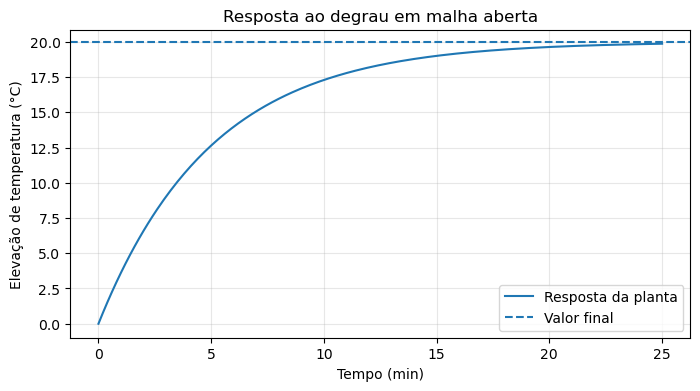

In [19]:
tau = 5.0
K = 2.0
u0 = 10.0
t = np.linspace(0, 25, 251)
x_aberta = K*u0*(1-np.exp(-t/tau))
print(f"Elevação após 5 min: {K*u0*(1-np.exp(-1)):.2f} °C")
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(t, x_aberta, label="Resposta da planta")
ax.axhline(K*u0, linestyle="--", label="Valor final")
ax.set(xlabel="Tempo (min)", ylabel="Elevação de temperatura (°C)", title="Resposta ao degrau em malha aberta")
ax.grid(alpha=.3); ax.legend(); plt.show()

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Discretização por Euler e validação</div>

A aproximação de Euler explícito para $dx/dt=f(x,u)$ é

$$
x_{k+1}=x_k+\ \Delta t\\ f(x_k,u_k)
$$

Para o modelo de primeira ordem,

$$
x_{k+1}=x_k+\ \frac{\ \Delta t}{\ \tau}(-x_k+Ku_k)
$$

Com $x_0=0$, $\ \Delta t=1$ min, $\ \tau=5$ min e $u=10$, o primeiro passo manual é $x_1=0+(1/5)(20)=4$ °C. A estabilidade de Euler para essa planta linear requer $0<\ \Delta t/\ \tau<2$, mas passos menores podem ser necessários para boa precisão.

In [20]:
def planta_euler(u, dt=0.1, tau=5.0, K=2.0, x0=0.0):
    u = np.asarray(u, dtype=float)
    if dt <= 0 or tau <= 0 or not np.isfinite(u).all():
        raise ValueError("Parâmetros ou entrada inválidos.")
    x = np.empty(len(u)+1)
    x[0] = x0
    for k in range(len(u)):
        x[k+1] = x[k]+dt*(-x[k]+K*u[k])/tau
    return x

dt = 0.1
entrada = np.full(250, 10.0)
x_num = planta_euler(entrada,dt=dt)
tempo = np.arange(len(x_num))*dt
x_exata = 20*(1-np.exp(-tempo/5))
print(f"Erro máximo de Euler: {np.max(np.abs(x_num-x_exata)):.4f} °C")

Erro máximo de Euler: 0.0742 °C


<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Controle proporcional: lei e interpretação</div>

A lei do **controle proporcional** é

$$u(t)=u_b+K_p e(t),$$

em que $u_b$ é o valor de polarização e $K_p$ o ganho proporcional. Para $u_b=0$, $K_p=1{,}5$ unidade/°C e $e=6$ °C, a ação é $u=9$ unidades.

A ação proporcional reage imediatamente ao erro, mas, em processos com ganho estático finito, geralmente permanece um erro em regime permanente após uma mudança de referência.

In [21]:
Kp = 1.5
erro = 6.0
u = Kp*erro
print(f"Ação proporcional: {u:.2f} unidades")

Ação proporcional: 9.00 unidades


<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Simulação de controle P em malha fechada</div>

**Malha fechada.** A cada instante, calculamos o erro a partir da temperatura simulada, determinamos a ação de controle e atualizamos a planta. Esse encadeamento é a essência de uma simulação dinâmica com realimentação.

Para simplificar a análise, trabalharemos com a elevação de temperatura $x=T-T_a$, uma referência $r_x=20$ °C acima do ambiente e ação $u$ não negativa, limitada a 30 unidades. A saturação é importante porque nenhum atuador fornece potência ilimitada.

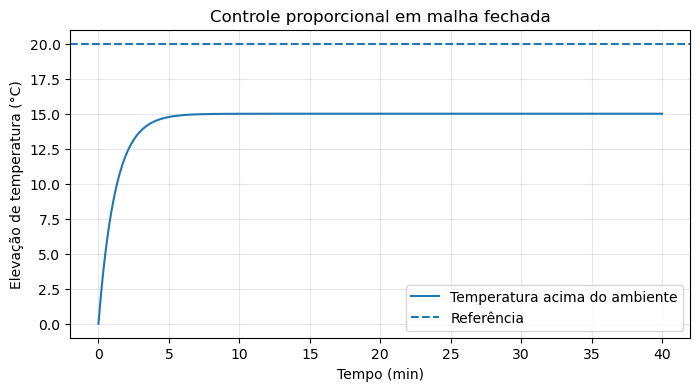

In [22]:
def simular_controle(tipo="P", kp=1.5, ki=0.0, kd=0.0, dt=0.1,
                     tf=40.0, tau=5.0, ganho=2.0, referencia=20.0,
                     u_min=0.0, u_max=30.0, pert_tempo=None,
                     perturbacao=0.0, antiwindup=True, filtro_d=0.0):
    if dt<=0 or tf<=0 or tau<=0 or ganho<=0 or u_max<=u_min:
        raise ValueError("Parâmetros físicos inválidos.")
    if tipo not in ("P","PI","PID"):
        raise ValueError("Tipo de controlador inválido.")
    n=round(tf/dt)
    if not np.isclose(n*dt,tf):
        raise ValueError("tf deve ser múltiplo de dt.")
    tempo=np.arange(n+1)*dt
    x=np.zeros(n+1)
    u=np.zeros(n)
    e=np.zeros(n)
    integral=0.0
    erro_ant=0.0
    derivada_filtrada=0.0
    for k in range(n):
        e[k]=referencia-x[k]
        derivada_bruta=(e[k]-erro_ant)/dt if k>0 else 0.0
        if filtro_d>0:
            alpha=dt/(filtro_d+dt)
            derivada_filtrada += alpha*(derivada_bruta-derivada_filtrada)
        else:
            derivada_filtrada=derivada_bruta
        termo_d=kd*derivada_filtrada if tipo=="PID" else 0.0
        termo_i=ki*integral if tipo in ("PI","PID") else 0.0
        u_livre=kp*e[k]+termo_i+termo_d
        u[k]=np.clip(u_livre,u_min,u_max)
        if tipo in ("PI","PID"):
            if not antiwindup or ((u_livre < u_max or e[k]<0) and
                                   (u_livre > u_min or e[k]>0)):
                integral += e[k]*dt
        d=perturbacao if pert_tempo is not None and tempo[k]>=pert_tempo else 0.0
        x[k+1]=x[k]+dt*(-x[k]+ganho*u[k]+d)/tau
        erro_ant=e[k]
    return tempo,x,u,e

tempo_p,x_p,u_p,e_p=simular_controle("P",kp=1.5)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(tempo_p,x_p,label="Temperatura acima do ambiente")
ax.axhline(20,linestyle="--",label="Referência")
ax.set(xlabel="Tempo (min)",ylabel="Elevação de temperatura (°C)",title="Controle proporcional em malha fechada")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Erro estacionário e ação proporcional</div>

**Erro estacionário.** Sem saturação e com controle P, em regime permanente temos $x=Ku$ e $u=K_p(r-x)$. Logo,

$$
x_{ss}=\ \frac{KK_p}{1+KK_p}r, \ \qquad e_{ss}=\ \frac{r}{1+KK_p}
$$

Para $K=2$, $K_p=1{,}5$ e $r=20$ °C, o erro esperado é $20/(1+3)=5$ °C e a elevação final é 15 °C. O modelo permite prever esse comportamento antes de executar o código.

In [23]:
erro_teorico=20/(1+2*1.5)
print(f"Erro estacionário teórico: {erro_teorico:.3f} °C")
print(f"Erro no final da simulação: {20-x_p[-1]:.3f} °C")
assert np.isclose(20-x_p[-1],erro_teorico,atol=0.01)

Erro estacionário teórico: 5.000 °C
Erro no final da simulação: 5.000 °C


<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Controle integral e eliminação do offset</div>

A ação integral acumula o erro:

$$
u(t)=K_p e(t)+K_i\ \int_0^t e(\ \xi)\ d \xi
$$

No tempo discreto, a integral pode ser aproximada por

$$
I_{k+1}=I_k+e_k\ \Delta t
$$

Se $e_k=2$ °C durante 0,5 min, o incremento é $1$ °C·min. A integral pode eliminar o erro estacionário de referência em condições adequadas, mas pode produzir oscilações e saturação se os ganhos forem excessivos.

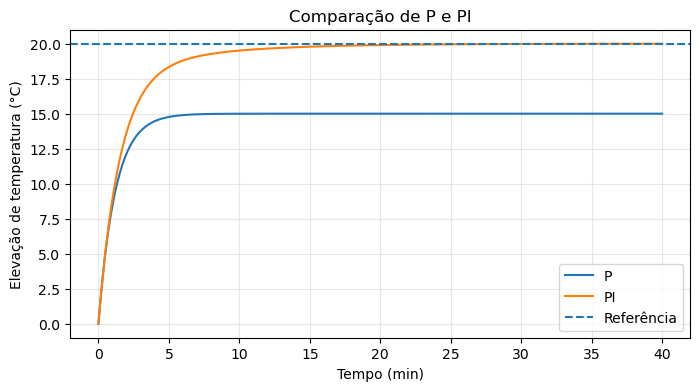

Erro final P: 5.000 °C; PI: 0.004 °C


In [24]:
tempo_pi,x_pi,u_pi,e_pi=simular_controle("PI",kp=1.5,ki=0.25)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(tempo_p,x_p,label="P")
ax.plot(tempo_pi,x_pi,label="PI")
ax.axhline(20,linestyle="--",label="Referência")
ax.set(xlabel="Tempo (min)",ylabel="Elevação de temperatura (°C)",title="Comparação de P e PI")
ax.grid(alpha=.3);ax.legend();plt.show()
print(f"Erro final P: {20-x_p[-1]:.3f} °C; PI: {20-x_pi[-1]:.3f} °C")

<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Controle derivativo e antecipação</div>

A ação derivativa considera a tendência de variação do erro:

$$
u_D(t)=K_d\ \frac{de(t)}{dt}
$$

Se o erro diminui de 6 para 4 °C em 1 min, a derivada aproximada é $-2$ °C/min. A ação derivativa pode reduzir a tendência de ultrapassagem, mas amplifica ruído de medição.

Em aplicações práticas, costuma-se filtrar a derivada e, frequentemente, derivar a variável medida em vez do erro para evitar o chamado *derivative kick* após mudanças bruscas da referência.

In [25]:
erro_anterior=6.0
erro_atual=4.0
dt_exemplo=1.0
derivada=(erro_atual-erro_anterior)/dt_exemplo
print(f"Derivada aproximada do erro: {derivada:.2f} °C/min")

Derivada aproximada do erro: -2.00 °C/min


<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Controlador PID e discretização</div>

A lei ideal do PID combina as três ações:

$$
u(t)=K_p e(t)+K_i\ \int_0^t e(\ \xi)\ d\ \xi+K_d\ \frac{de(t)}{dt}
$$

Em forma discreta, a derivada pode ser aproximada por $(e_k-e_{k-1})/\ \Delta t$. A implementação construída anteriormente permite escolher P, PI ou PID. O filtro de derivada é representado por uma constante de tempo didática.

**Atenção:** os valores de ganho utilizados são exemplos de simulação, não recomendações de sintonia para equipamentos reais.

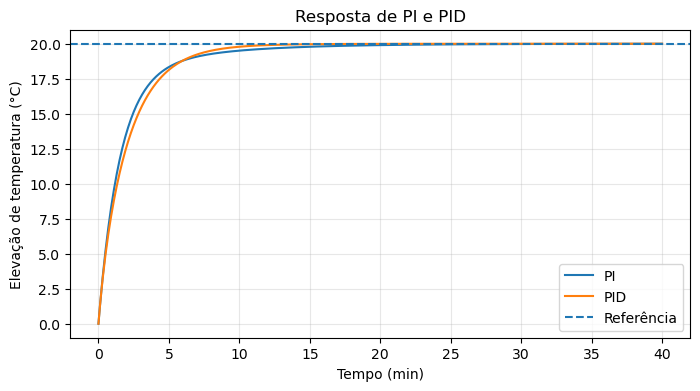

In [26]:
tempo_pid,x_pid,u_pid,e_pid=simular_controle(
    "PID",kp=1.5,ki=0.25,kd=0.5,filtro_d=0.5)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(tempo_pi,x_pi,label="PI")
ax.plot(tempo_pid,x_pid,label="PID")
ax.axhline(20,linestyle="--",label="Referência")
ax.set(xlabel="Tempo (min)",ylabel="Elevação de temperatura (°C)",title="Resposta de PI e PID")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Saturação do atuador e windup</div>

**Saturação do atuador.** Um aquecedor não fornece potência negativa nem potência infinita. Representaremos esses limites por

$$
u_{aplicado}=\ \min(u_{max},\ \max(u_{min},u_{calculado}))
$$

Quando a saída do controlador satura, a ação integral pode continuar acumulando erro, fenômeno conhecido como **windup**. Isso pode retardar a recuperação quando o processo volta a operar dentro da faixa disponível.

A saturação não deve ser tratada apenas como um detalhe de programação: ela representa uma restrição física.

In [27]:
tempo_sat,x_sat,u_sat,e_sat=simular_controle(
    "PI",kp=1.5,ki=0.8,referencia=40,u_max=12,tf=30,antiwindup=False)
print(f"Limites da ação aplicada: {u_sat.min():.1f} a {u_sat.max():.1f}")
print(f"Temperatura final acima do ambiente: {x_sat[-1]:.2f} °C")

Limites da ação aplicada: 12.0 a 12.0
Temperatura final acima do ambiente: 23.94 °C


<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Anti-windup por integração condicional</div>

**Anti-windup por integração condicional.** Uma estratégia didática consiste em suspender o acúmulo da integral quando o controlador está saturado e o erro tende a aprofundar a saturação.

A estratégia implementada no simulador permite integrar quando o sinal do erro favorece a saída da saturação. Em aplicações industriais, outras técnicas — como *back-calculation* — podem ser mais adequadas, especialmente quando há mudanças de modo de operação.

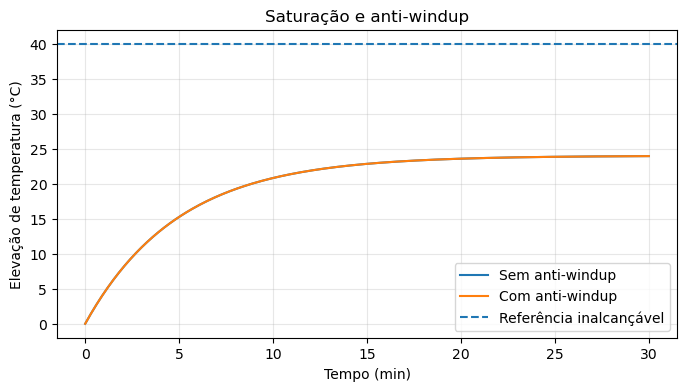

In [28]:
tempo_aw,x_aw,u_aw,e_aw=simular_controle(
    "PI",kp=1.5,ki=0.8,referencia=40,u_max=12,tf=30,antiwindup=True)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(tempo_sat,x_sat,label="Sem anti-windup")
ax.plot(tempo_aw,x_aw,label="Com anti-windup")
ax.axhline(40,linestyle="--",label="Referência inalcançável")
ax.set(xlabel="Tempo (min)",ylabel="Elevação de temperatura (°C)",title="Saturação e anti-windup")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Perturbações e rejeição de carga</div>

**Rejeição de perturbações.** Uma alteração na carga térmica pode ser representada por um termo adicional $d(t)$ no modelo:

$$
\tau\ \frac{dx}{dt}=-x+Ku+d(t)
$$

Para $d=-5$ °C (na forma normalizada do modelo), a tendência inicial é reduzir a temperatura. Um controlador com ação integral pode corrigir o desvio em regime permanente, desde que exista autoridade de controle suficiente e a malha seja estável.

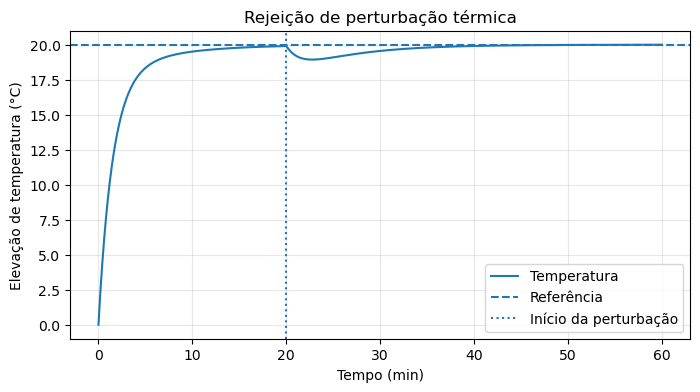

In [29]:
t_pert,x_pert,u_pert,e_pert=simular_controle(
    "PI",kp=1.5,ki=0.25,pert_tempo=20,perturbacao=-5,tf=60)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(t_pert,x_pert,label="Temperatura")
ax.axhline(20,linestyle="--",label="Referência")
ax.axvline(20,linestyle=":",label="Início da perturbação")
ax.set(xlabel="Tempo (min)",ylabel="Elevação de temperatura (°C)",title="Rejeição de perturbação térmica")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Sintonia e comparação de desempenhos</div>

**Sintonia e avaliação.** Uma resposta mais rápida não é necessariamente melhor: ganhos elevados podem provocar ultrapassagem, oscilações ou atuação excessiva.

Uma medida simples de desempenho é a integral do erro absoluto,

$$
IAE\ \approx\ \sum_{k=0}^{N-1}|e_k|\ \Delta t
$$

O IAE combina magnitude e duração do erro, mas não informa sozinho o esforço do atuador, a robustez ou a segurança da operação. Vamos comparar três ganhos proporcionais mantendo os demais parâmetros constantes.

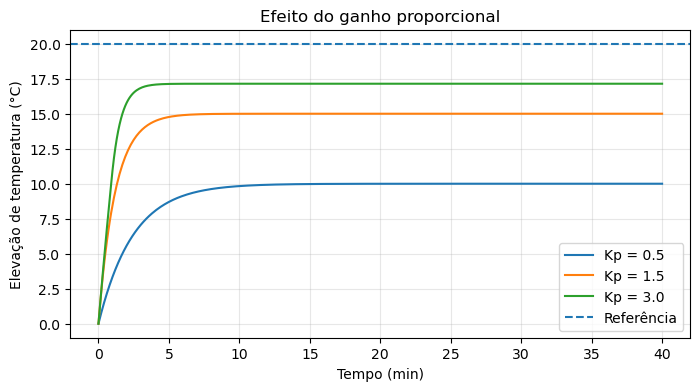

Kp=0.5: IAE=425.00 °C·min; erro final=10.00 °C
Kp=1.5: IAE=218.75 °C·min; erro final=5.00 °C
Kp=3.0: IAE=130.71 °C·min; erro final=2.86 °C


In [30]:
resultados=[]
fig,ax=plt.subplots(figsize=(8,4))
for kp_teste in [0.5,1.5,3.0]:
    tt,xx,uu,ee=simular_controle("P",kp=kp_teste)
    iae=np.sum(np.abs(ee))*0.1
    resultados.append((kp_teste,iae,20-xx[-1]))
    ax.plot(tt,xx,label=f"Kp = {kp_teste}")
ax.axhline(20,linestyle="--",label="Referência")
ax.set(xlabel="Tempo (min)",ylabel="Elevação de temperatura (°C)",title="Efeito do ganho proporcional")
ax.grid(alpha=.3);ax.legend();plt.show()
for kp_teste,iae,erro_final in resultados:
    print(f"Kp={kp_teste:.1f}: IAE={iae:.2f} °C·min; erro final={erro_final:.2f} °C")

<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Instrumentação: ruído e filtragem</div>

**Instrumentação e Controle.** A variável controlada é conhecida por meio de uma medição. Se o sensor apresenta ruído, o controlador pode reagir a oscilações que não correspondem a mudanças reais do processo.

Um filtro de primeira ordem pode suavizar as medições, mas introduz atraso. O compromisso entre atenuação de ruído e rapidez da malha deve ser estudado, especialmente quando se utiliza ação derivativa.

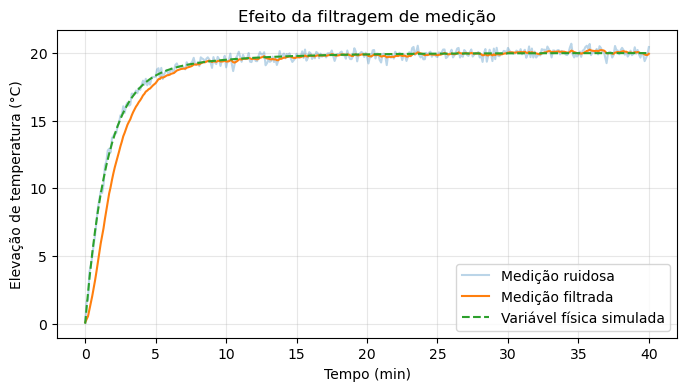

In [31]:
rng=np.random.default_rng(21)
tempo_ruido=np.arange(len(x_pi))*0.1
medicao_ruidosa=x_pi+rng.normal(0,0.3,len(x_pi))
alpha=0.15
medicao_filtrada=np.empty_like(medicao_ruidosa)
medicao_filtrada[0]=medicao_ruidosa[0]
for k in range(1,len(medicao_ruidosa)):
    medicao_filtrada[k]=alpha*medicao_ruidosa[k]+(1-alpha)*medicao_filtrada[k-1]
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(tempo_ruido,medicao_ruidosa,alpha=.3,label="Medição ruidosa")
ax.plot(tempo_ruido,medicao_filtrada,label="Medição filtrada")
ax.plot(tempo_ruido,x_pi,linestyle="--",label="Variável física simulada")
ax.set(xlabel="Tempo (min)",ylabel="Elevação de temperatura (°C)",title="Efeito da filtragem de medição")
ax.grid(alpha=.3);ax.legend();plt.show()

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Aplicação integradora: tanque aquecido</div>

**Projeto integrador — Tanque aquecido.** Considere temperatura ambiente de 25 °C e referência de 45 °C. A elevação desejada é $x_{SP}=45-25=20$ °C. O tanque é descrito pelo modelo de primeira ordem com $\\tau=5$ min e $K=2$ °C/unidade.

O cálculo manual do valor estacionário necessário é $u_{ss}=x_{SP}/K=20/2=10$ unidades. Um controlador PI pode ajustar automaticamente a ação a esse valor. Vamos representar temperatura absoluta, referência e potência aplicada.

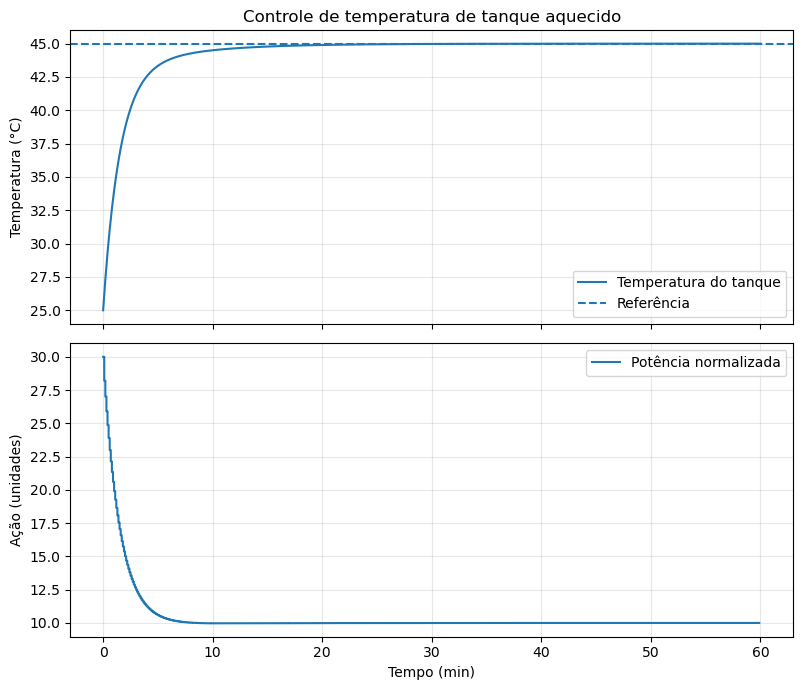

Temperatura final: 45.000 °C
Ação final: 10.000 unidades


In [32]:
T_ambiente=25.0
T_SP=45.0
t_int,x_int,u_int,e_int=simular_controle(
    "PI",kp=1.5,ki=0.25,referencia=T_SP-T_ambiente,tf=60)
T_tanque=T_ambiente+x_int
fig,axs=plt.subplots(2,1,figsize=(8,7),sharex=True)
axs[0].plot(t_int,T_tanque,label="Temperatura do tanque")
axs[0].axhline(T_SP,linestyle="--",label="Referência")
axs[0].set(ylabel="Temperatura (°C)",title="Controle de temperatura de tanque aquecido")
axs[0].grid(alpha=.3);axs[0].legend()
axs[1].step(t_int[:-1],u_int,where="post",label="Potência normalizada")
axs[1].set(xlabel="Tempo (min)",ylabel="Ação (unidades)")
axs[1].grid(alpha=.3);axs[1].legend()
plt.tight_layout();plt.show()
print(f"Temperatura final: {T_tanque[-1]:.3f} °C")
print(f"Ação final: {u_int[-1]:.3f} unidades")

<div id="secao-19" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">19. Exercícios de consolidação</div>

**Exercício 1 — Identificação de variáveis.** Em um trocador de calor aquecido por vapor, identifique variável controlada, variável manipulada, referência e duas possíveis perturbações. Explique o sentido físico da ação.

**Exercício 2 — Resposta dinâmica.** Para $\\tau=4$ min, $K=3$ °C/unidade e degrau de 5 unidades, calcule manualmente a resposta após uma constante de tempo e implemente o gráfico.

**Exercício 3 — Euler.** Discretize $\\tau\\dot x=-x+Ku$ e calcule os dois primeiros passos para $\\Delta t=1$ min, $x_0=0$, $\\tau=4$, $K=2$ e $u=6$.

**Exercício 4 — Controle P.** Para $K=2$, $K_p=2$ e referência de 15 °C acima do ambiente, determine o erro estacionário e compare com a simulação.

**Exercício 5 — Controle PI.** Compare os resultados para $K_i=0{,}1$, $0{,}3$ e $0{,}6$, mantendo $K_p=1{,}5$. Discuta rapidez, ultrapassagem e ação de controle.

**Exercício 6 — Saturação.** Limite o atuador a 8 unidades. Determine a maior elevação de temperatura alcançável no modelo e explique por que a integral não consegue superar esse limite.

**Exercício 7 — Perturbações.** Aplique uma perturbação negativa após 15 min e compare o desempenho de P e PI por meio do erro e do IAE.

**Exercício 8 — Instrumentação.** Introduza ruído na variável medida e compare duas intensidades de filtragem. Explique por que o sinal mais suave não é necessariamente o melhor para controle.

**Desafio integrador.** Modifique o modelo para um tanque com duas correntes de entrada e aquecimento externo. Deduzir o balanço de energia deve preceder a programação do controlador.

<div id="secao-20" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">20. Conclusões</div>

Neste notebook, partimos de um balanço de energia para construir um modelo dinâmico, discretizá-lo e implementar uma malha de realimentação. As ações proporcional, integral e derivativa foram relacionadas a seus efeitos físicos, limitações e cuidados de implementação.

A principal conclusão é que **um controlador deve ser compreendido como parte de um sistema físico e instrumentado**. A qualidade do controle depende do modelo, da medição, da sintonia, das restrições do atuador e da resposta às perturbações. O estudo prepara o próximo notebook, dedicado à otimização de processos químicos.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>